# Практика 1
## Реализация с нуля
### Подготовка данных

In [8]:
data_frame <- read.csv('./prac-1.csv')
data_frame[1] <- NULL

for (index in c(1:10, 13:17)) {
    data_frame[[index]] <- as.numeric(factor(data_frame[[index]]))
}

split_index <- 34
data_train <- data_frame[1:split_index, ]
data_test <- data_frame[(split_index + 1):nrow(data_frame), ]

head(data_train)
head(data_test)

,Как.вы.себя.чувствуете..когда.оказались.в.центре.внимания.в.малознакомой.компании.,Как.чаще.всего.принимаются.ваши.повседневные.решения.о.покупках.,Покупая.сложную.технику.или.мебель..какой.подход.вам.ближе.,Что.вы.выберете.при.покупке.повседневной.вещи.,Быстро.ли.твой.телефон.разряжается.,Ты.часто.снимаешь.на.телефон.фото.видео.,При.выборе.предмета.интерьера.или.одежды..что.станет.решающим.фактором.,Часто.ли.твой.телефон.тормозит.лагает.,Тебе.важно..чтобы.все.приложения.со.временем.работали.одинаково.,Любите.ли.вы.путешествовать.,Как.часто.ты.меняешь.смартфон.на.новый..Введите.число.лет..целое..например..2.,Как.часто.вы.играете.в.видеоигры..Введите.примерное.кол.во.часов.в.неделю..целое..например..5.,Часто.ли.вы.публикуете.фотографии.или.видео.в.социальных.сетях.,Часто.ли.вы.смотрите.фильмы.и.сериалы.на.телефоне.,Цвет.глаз...С.большой.буквы.в.именительном.падеже.единственное.число..например..Зеленый.,Ближайшая.станция.метро...Точное.название..например..Преображенская.площадь..Сокольники.и.т.п..,У.тебя.айфон.или.андроид.
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2,1,2,1,1,2,1,2,1,1,4,5,2,1,2,37,1
2,2,1,2,1,1,1,2,2,1,1,3,1,1,1,7,6,1
3,2,1,2,2,2,1,1,2,1,1,3,1,2,2,7,5,1
4,1,1,2,1,1,2,2,2,1,1,3,0,2,2,14,2,1
5,2,1,2,2,1,2,2,1,1,1,4,6,2,2,2,9,2
6,2,1,2,2,1,2,2,2,1,2,5,8,2,2,8,25,2


,Как.вы.себя.чувствуете..когда.оказались.в.центре.внимания.в.малознакомой.компании.,Как.чаще.всего.принимаются.ваши.повседневные.решения.о.покупках.,Покупая.сложную.технику.или.мебель..какой.подход.вам.ближе.,Что.вы.выберете.при.покупке.повседневной.вещи.,Быстро.ли.твой.телефон.разряжается.,Ты.часто.снимаешь.на.телефон.фото.видео.,При.выборе.предмета.интерьера.или.одежды..что.станет.решающим.фактором.,Часто.ли.твой.телефон.тормозит.лагает.,Тебе.важно..чтобы.все.приложения.со.временем.работали.одинаково.,Любите.ли.вы.путешествовать.,Как.часто.ты.меняешь.смартфон.на.новый..Введите.число.лет..целое..например..2.,Как.часто.вы.играете.в.видеоигры..Введите.примерное.кол.во.часов.в.неделю..целое..например..5.,Часто.ли.вы.публикуете.фотографии.или.видео.в.социальных.сетях.,Часто.ли.вы.смотрите.фильмы.и.сериалы.на.телефоне.,Цвет.глаз...С.большой.буквы.в.именительном.падеже.единственное.число..например..Зеленый.,Ближайшая.станция.метро...Точное.название..например..Преображенская.площадь..Сокольники.и.т.п..,У.тебя.айфон.или.андроид.
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
35,2,2,2,1,2,2,1,2,1,1,5,0,2,1,12,29,2
36,1,1,1,1,2,1,2,1,1,2,6,130,1,2,9,1,2
37,2,1,2,2,1,1,2,2,1,1,5,1,1,1,1,26,1
38,2,1,2,2,1,2,2,2,1,1,5,2,2,2,2,32,2
39,1,1,1,1,2,2,2,2,2,1,4,20,2,2,7,24,2
40,2,1,2,1,1,2,2,2,1,1,2,1,2,1,10,33,1


### Реализация функции предсказания и замера точности

In [9]:
knn_predict <- function(data_test, data_train, k) {
    train_len <- nrow(data_train)
    predictions <- c()
    
    for (i in 1:nrow(data_test)) {
        target <- data_test[i, ]
        distances <- c()
        
        for (j in 1:train_len) {
            distances <- c(distances, dist(rbind(target, data_train[j, ])))
        }
    
        closest_neighbours_indices <- order(distances)[1:k]
        closest_neighbours_answers <- data_train$У.тебя.айфон.или.андроид.[closest_neighbours_indices]
    
        prediction <- as.numeric(names(sort(table(closest_neighbours_answers), decreasing = TRUE))[1])
        predictions <- c(predictions, prediction)
    }
    
    predictions
}

knn_accuracy <- function(predictions, answers) {
    sum(predictions == answers) / length(predictions)
}

### Предсказание при k = 3

In [10]:
predictions <- factor(knn_predict(data_test, data_train, 3), labels = c("Андроид", "Айфон"))
answers <- factor(data_test$У.тебя.айфон.или.андроид, labels = c("Андроид", "Айфон"))

data.frame(
    Предсказание = predictions,
    Ответ = answers
)

sprintf("Точность при k = 3: %s", knn_accuracy(predictions, answers))

Предсказание,Ответ
<fct>,<fct>
Андроид,Айфон
Айфон,Айфон
Айфон,Андроид
Айфон,Айфон
Айфон,Айфон
Андроид,Андроид
Андроид,Андроид
Айфон,Айфон
Андроид,Андроид


[1] "Точность при k = 3: 0.8"

### Проверка точности при различном k

3,5,7,9,11,13,15,17,19,21,23
0.8,0.9,0.8,0.8,0.7,0.6,0.7,0.6,0.6,0.6,0.6


[1] "Наибольшая точность при k = 5"

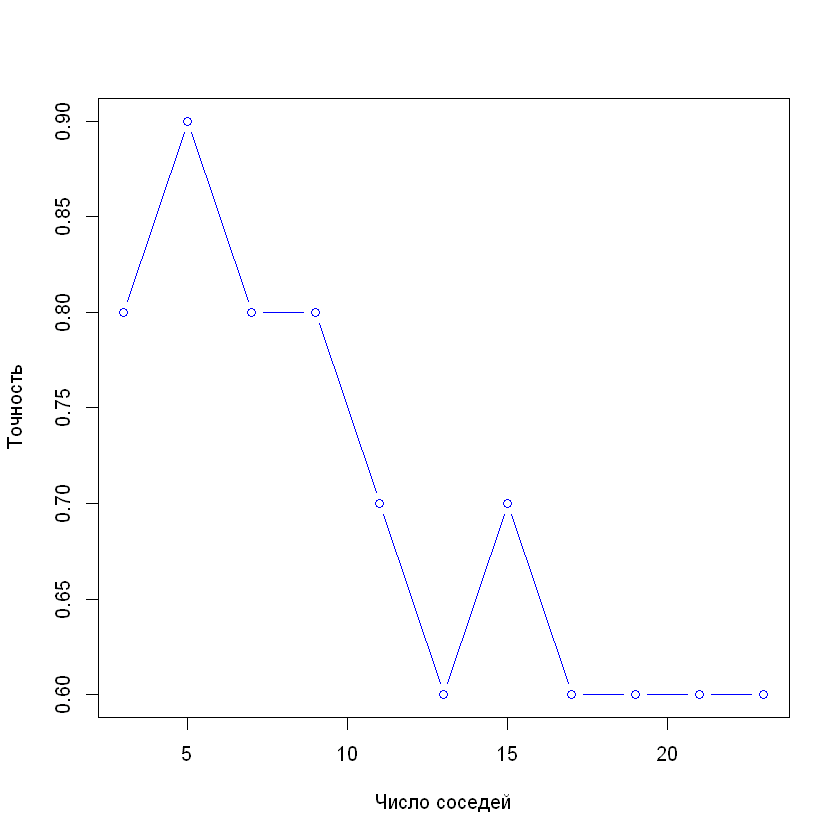

In [11]:
x <- c()
y <- c()

for (k in seq(3, 23, 2)) {
    x <- c(x, k)
    y <- c(y, knn_accuracy(knn_predict(data_test, data_train, k), data_test$У.тебя.айфон.или.андроид.))
}

t(as.matrix(setNames(y, x)))
sprintf("Наибольшая точность при k = %s", x[which.max(y)])
plot(
    x = x,
    y = y,
    type = "b",
    xlab = "Число соседей",
    ylab = "Точность",
    col = "blue"
)

## Реализация с использованием библиотеки для работы с предсказательными моделями
### Подготовка данных

In [14]:
library(caret)

df <- read.csv('./prac-1.csv')
df[1] <- NULL

for (index in c(1:10, 13:17)) {
    df[[index]] <- factor(df[[index]])
}

#part <- createDataPartition(y = df[[17]], p = 0.8, list = FALSE)
#data_train <- df[part, ]
#data_test <- df[-part, ]

split_index <- 34
data_train <- df[1:split_index, ]
data_test <- df[(split_index + 1):nrow(data_frame), ]

### Предсказание при k = 3

In [15]:
model <- train(
    У.тебя.айфон.или.андроид. ~.,
    data = data_train,
    method = "knn",
    tuneGrid = data.frame(k = 3),
    trControl = trainControl(method = "none")
)

predictions <- predict(model, newdata = data_test)
answers <- data_test$У.тебя.айфон.или.андроид.

data.frame(
    Предсказание = predictions,
    Ответ = answers
)

confusionMatrix(predictions, answers)

Предсказание,Ответ
<fct>,<fct>
Айфон,Андроид
Андроид,Андроид
Айфон,Айфон
Айфон,Андроид
Андроид,Андроид
Айфон,Айфон
Айфон,Айфон
Андроид,Андроид
Андроид,Айфон


Confusion Matrix and Statistics

          Reference
Prediction Айфон Андроид
   Айфон       3       2
   Андроид     1       4
                                          
               Accuracy : 0.7             
                 95% CI : (0.3475, 0.9333)
    No Information Rate : 0.6             
    P-Value [Acc > NIR] : 0.3823          
                                          
                  Kappa : 0.4             
                                          
 Mcnemar's Test P-Value : 1.0000          
                                          
            Sensitivity : 0.7500          
            Specificity : 0.6667          
         Pos Pred Value : 0.6000          
         Neg Pred Value : 0.8000          
             Prevalence : 0.4000          
         Detection Rate : 0.3000          
   Detection Prevalence : 0.5000          
      Balanced Accuracy : 0.7083          
                                          
       'Positive' Class : Айфон           
            

### Проверка точности при различном k

3,5,7,9,11,13,15,17,19,21,23
0.8,0.6,1,0.7,0.7,0.8,0.8,0.8,0.8,0.8,0.6


[1] "Наибольшая точность при k = 7"

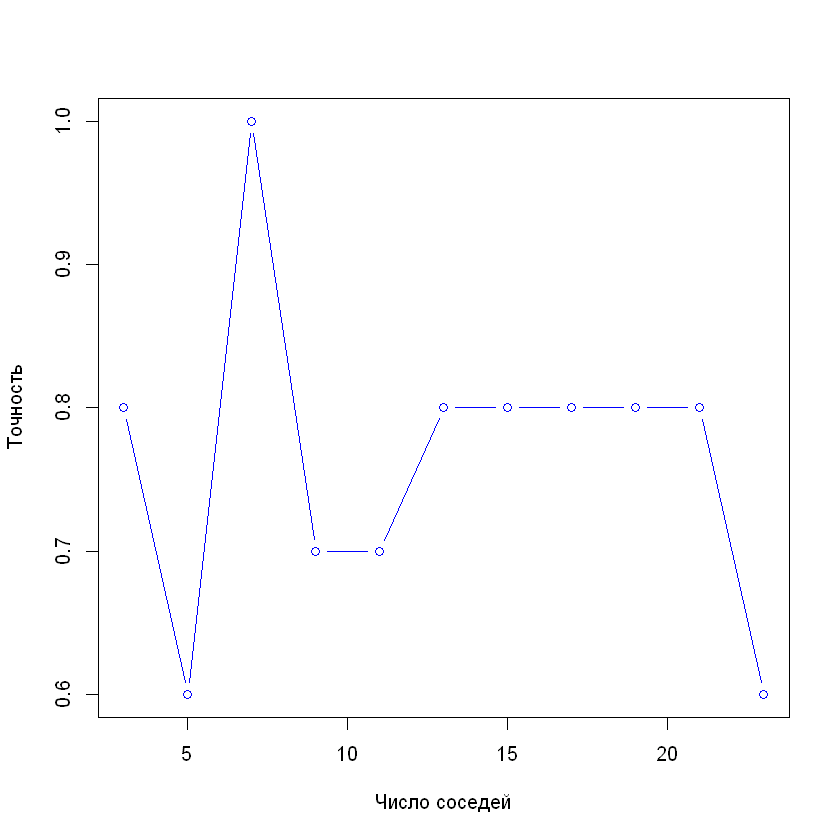

In [16]:
x <- c()
y <- c()

for (k in seq(3, 23, 2)) {
    x <- c(x, k)
    
    model <- train(
        У.тебя.айфон.или.андроид. ~.,
        data = data_train,
        method = "knn",
        tuneGrid = data.frame(k = k),
        trControl = trainControl(method = "none")
    )
    
    predictions <- predict(model, newdata = data_test)
    answers <- data_test$У.тебя.айфон.или.андроид.

    y <- c(y, confusionMatrix(predictions, answers)$overall["Accuracy"])
}

t(as.matrix(setNames(y, x)))
sprintf("Наибольшая точность при k = %s", x[which.max(y)])
plot(
    x = x,
    y = y,
    type = "b",
    xlab = "Число соседей",
    ylab = "Точность",
    col = "blue"
)